# Basic Model for Binary Data
The simplest form of logistic regression is when the outcome variable is *binary*. For instance, in a clinical dataset we might define the outcome $y$ as

$$
y_{i} = 
\begin{cases} 
    0 & \text{no disease} \\
    1 & \text{disease},   \\ 
\end{cases}
$$

or in a study investigating long term recovery we might have

$$
y_{i} = 
\begin{cases} 
    0 & \text{not recovered} \\
    1 & \text{recovered}.   \\ 
\end{cases}
$$

In pre-clinical work, binary outcomes can correspond to whether an individual rat survived a given treatment

$$
y_{i} = 
\begin{cases} 
    0 & \text{survived}       \\
    1 & \text{died},  \\ 
\end{cases}
$$

whereas in a field like development psychology, a binary outcome could indicate whether a particular child has achieved a certain developmental milestone

$$
y_{i} = 
\begin{cases} 
    0 & \text{failed}   \\
    1 & \text{passed}.  \\ 
\end{cases}
$$

In all cases, the outcome only consists of 1's and 0's and is therefore *categorical* in nature, rather than continuous. These categories are referred to generically, and sometimes rather morbidly, as "successes" and "failures".

## Distribution
As discussed last week, the first core element of a GLM is an assumed marginal distribution from the exponential family. For binary logistic regression, the assumed distribution is *Bernoulli*.


### The Bernoulli Distribution
As discussed last week, the Bernoulli distribution is a special case of the binomial distribution where the outcome is binary and the distribution is solely parameterised the *probability of success*. Our probability model is therefore:

$$
    y_{i} \sim \text{Bern}\left(\pi_{i}\right)
$$

where the mean and variance functions are

$$
\begin{align*}
    E(y_{i})          &= \mu_{i} = \pi_{i} \\
    \text{Var}(y_{i}) &= \pi_{i}(1-\pi_{i}). 
\end{align*}
$$

As such, our main concern is modelling $\pi_{i}$ as a function of the predictor variables. In other words, we want to know how the probability of "success" changes with either the different values of a continuous predictor, or the different groups of a categorical predictor.

You can visualise the Bernoulli distribution and how it changes for different values of $\pi$ in the [Probability Playground](https://probabilityplayground.com/bernoulli.html).

## Link Function
As also discussed last week, the second core element of a GLM is a link function, used to connect the output from linear regression to a value suitable for use as a parameter of the assumed distribution. Under a Bernoulli distribution, the parameter of interest is the probability of success $\pi_{i}$. As such, a link function is required that will transform the regression prediction into a viable probability of success.


### Link Function Principles
Given that our parameter of interest is the probability of success, we want some way of modelling this as a function of different numbers of predictor variables. We could start simply with linear regression

$$
    \pi_{i} = \beta_{0} + \beta_{1}x_{i} + \dots \beta_{k}x_{k}.
$$

However, this is unlikely to work because there is nothing to constrain the regression prediction to the interval $(0,1)$. So, we cannot just use linear regression and expect it to give us a probability. 

Instead, we can define a transformation of the regression prediction into a probability using some suitable function we will call $g$. Our model then becomes

$$
    g(\pi_{i}) = \beta_{0} + \beta_{1}x_{i} + \dots \beta_{k}x_{k}
$$

or, alternatively,

$$
    \pi_{i} = g^{-1}(\beta_{0} + \beta_{1}x_{i} + \dots \beta_{k}x_{k})
$$

where $g^{-1}$ is the *inverse* of $g$, performing the transformation in reverse. In words, this is saying that the regression prediction produces some value which, when passed through $g^{-1}$, will give us a probability $\pi_{i}$. Or, equivalently, that the regression prediction produces some value on the scale of $g(\pi_{i})$. More generally, $g$ is known as the *link function* and $g^{-1}$ is known as the *inverse link function*.

```{tip} Link vs Inverse Link
The precise definition of which transformation is considered the *link function* and which is the *inverse* does not really matter. The direction shown above is the convention for GLMs such that the direct transformation of the regression prediction is considered the *inverse*. This is helpful because we typically want to think of our model in terms of the regression formulation, rather than a transformed version of the regression equation. Thus, the link function converts the parameters of the distribution onto a scale that can be modelled using linear regression.  
```

### The Logit Link
In terms of defining what $g$ and $g^{-1}$ actually do, there are many possibilities. Most GLMs have a typical link function that they use, but this can be changed. So long as the function meets the requirements of the distribution parameter, it does not really matter. However there are some link functions that make the output of a the regression equal to the value of the $\theta$ parameter in the exponential form. These are known as *canonical* links and tend to be the default choice.

For *logistic* regression, the canonical link function is the *logit* transformation which is defined, for some probability $p$, as

$$
\log\left(\frac{p}{1 - p}\right).
$$

In the context of a GLM, this gives

$$
    \log\left(\frac{\pi_{i}}{1-\pi_{i}}\right) = \beta_{0} + \beta_{1}x_{i} + \dots \beta_{k}x_{k}
$$

with an inverse link function of

$$
    \pi_{i} = \frac{e^{\beta_{0} + \beta_{1}x_{i} + \dots \beta_{k}x_{k}}}{1 + e^{\beta_{0} + \beta_{1}x_{i} + \dots \beta_{k}x_{k}}}.
$$

In simple terms, the logit calculates the *log of the odds of success*. The probability is first converted into the odds, which are defined in the range $[0,\infty)$. This stretches probability into a much wider range. However, odds are awkward because everything below a probability of 50% is squashed into values between 0 and 1, whereas everything above can go from 1 to $\infty$. Taking the log of the odds removes this squash, allows the values to be negative and places the odds on an *additive* scale suitable for linear regression. 

We will explore this link function in much greater detail in the associated workshop, so do not worry if you do not fully understand all of this at the moment. The more practical understanding is that the logit transforms the straight regression line into an S-shaped curve bounded between 0 and 1, thus transforming the regression output into a probability. This is demonstrated in the comparison below.


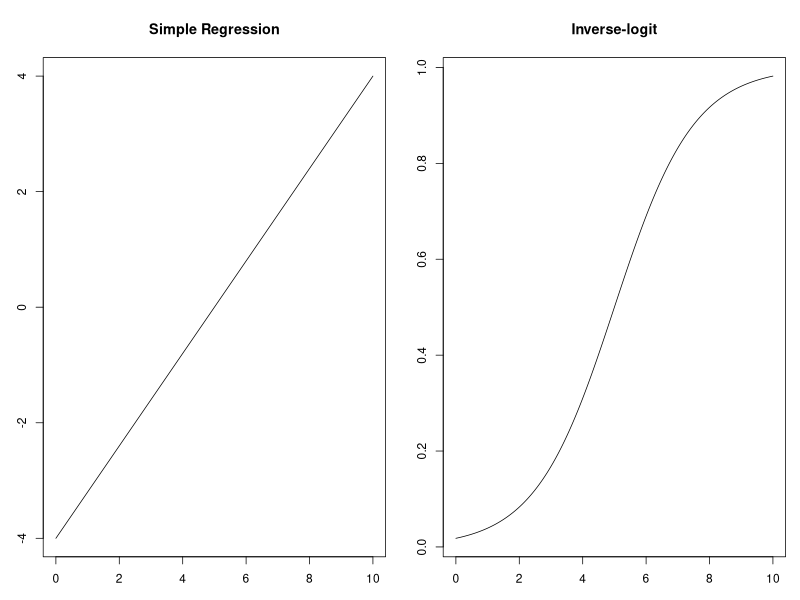

In [1]:
# Simple regression
x      <- seq(0, 10, length.out = 200)
beta.0 <- -4
beta.1 <- 0.8
yhat   <- beta.0 + beta.1*x

# Convert regression prediction to probability
prob <- exp(yhat) / (1 + exp(yhat))

# Plot in a 1x2 grid with reduced margins
par(mfrow=c(1,2), mar=c(3, 3, 4, 1))

# Plot regression
plot(x, yhat, type='l', main='Simple Regression', xlab='', ylab='')

# Plot transformation
plot(x, prob, type='l', main='Inverse-logit', , xlab='', ylab='')

```{tip} Alternative Link Functions
There are alternatives to the logit link that you may come across. One such example is the *probit* link function, with the associated *probit regression* model. The specifics of what the probit transformation does compared to the logit are beyond the current scope as, practically, it makes little difference in terms of model fit. As such, the important point is that the link function is a *choice*, and that there can be other possibilities.
```

## Parameter Estimation
In terms of estimating the parameters, there is not too much we need to understand to use logistic regression. The estimation proceeds using maximum likelihood and the exponential form of the model. As discussed last week, for the Bernoulli distribution the variance is directly connected to the mean and the dispersion parameter $\phi$ is set to 1. As such, the only value to estimate is $\theta_{i}$. This depends upon the mean of the distribution, which in turn depends upon $\pi_{i}$, which we define as dependant upon the regression coefficients via the link function.  

In practical terms, understanding the estimation process in any more detail is of limited consequence when using logistic regression. There will be multiple iterations reported, due to maximum likelihood, but these usually complete so quickly that the iterative nature of the estimation is not noticeable. The output may also report that $\phi = 1$, which we now understand. However, the bigger practical concern is how we then *interpret* the estimates. This is one aspect of logistic regression that takes some practice and can trip people up. As such, we will dedicate the next part of the lesson to actually understanding what the logistic regression output means.

:::{tip .simple icon=false} What You Now Know
In this section, we have discussed ... . After reading this section, you should have a good sense of:
- Something
- Something else
:::